# Trying MNIST Again

From memory this time

want to try and implement

- batchnorm
- adam
- regularisation (dropout whatever)

In [1]:
from sklearn.datasets import fetch_openml
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Import datast
mnist = fetch_openml('mnist_784', version=1)
X, y = torch.tensor(mnist["data"].to_numpy()), torch.tensor(mnist["target"].to_numpy().astype(int))

In [2]:
# train test split
X_train_raw, X_test_raw, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

# minmax scaling - scaled based on train set to avoid leakage
X_min = X_train_raw.min() # note this would return just one scaler
X_max = X_train_raw.max()

X_train = (X_train_raw - X_min)/(X_max - X_min) # , would broadcast across both dims to apply to every element
X_test = (X_test_raw - X_min)/(X_max - X_min)

In [32]:
# lets create a network with one hidden layer of 256
# 784 -> 256 -> 10

# initialise our parameters
# need layer 1 weights 784 * 256, then biases 256
# relu activation?
# layer 2 weights 256 * 10, 10 biases
# then softmax activation

# cross entropy loss
n_train = X_train.shape[0]
inputs = X.shape[1]
layer1 = 256
layer2 = 128
out = 10


In [49]:
# init

g = torch.Generator()
g.manual_seed(42)

W1 = torch.randn(inputs, layer1, generator=g) * (2/inputs)**0.5
b1 = torch.zeros(layer1)

W2 = torch.randn(layer1, layer2, generator=g) * (2/layer1)**0.5
b2 = torch.zeros(layer2)

W3 = torch.randn(layer2, out, generator=g) * (2/layer2)**0.5
b3 = torch.zeros(out)


params = [W1, b1, W2, b2, W3, b3]
for p in params:
    p.requires_grad = True


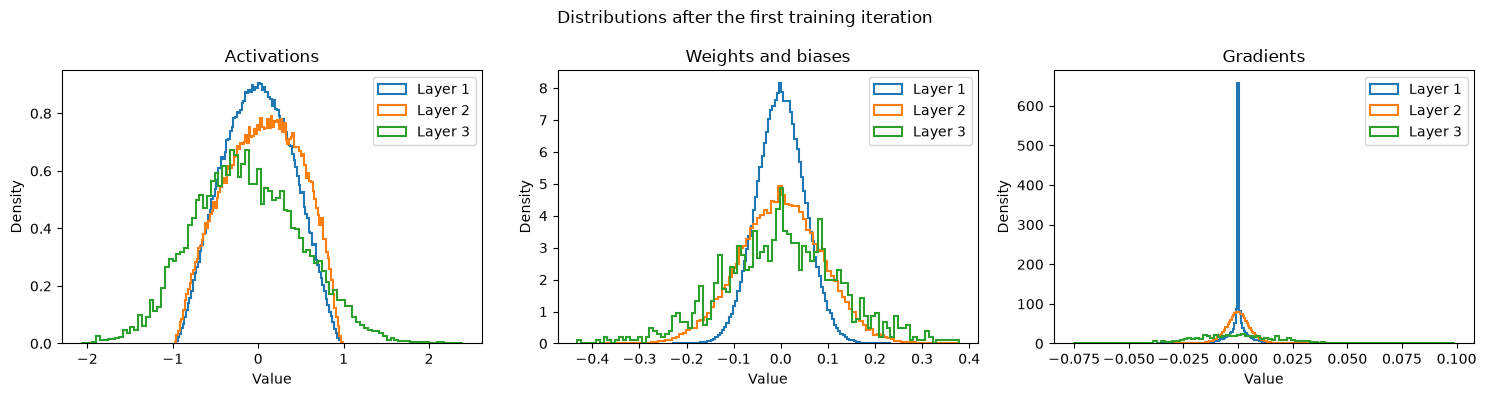

iteration 0, loss = 2.456759214401245, acc = 0.0820000022649765
iteration 10, loss = 1.0220527648925781, acc = 0.75
iteration 20, loss = 0.767359733581543, acc = 0.7960000038146973
iteration 30, loss = 0.5992898344993591, acc = 0.8399999737739563
iteration 40, loss = 0.5636340975761414, acc = 0.847000002861023
iteration 50, loss = 0.543659508228302, acc = 0.8600000143051147
iteration 60, loss = 0.4376675486564636, acc = 0.8830000162124634
iteration 70, loss = 0.4256649315357208, acc = 0.8849999904632568
iteration 80, loss = 0.41796720027923584, acc = 0.8889999985694885
iteration 90, loss = 0.4045485258102417, acc = 0.8889999985694885
iteration 100, loss = 0.3854343891143799, acc = 0.8920000195503235
iteration 110, loss = 0.4019957184791565, acc = 0.8849999904632568
iteration 120, loss = 0.3295217752456665, acc = 0.9210000038146973
iteration 130, loss = 0.37169066071510315, acc = 0.8989999890327454
iteration 140, loss = 0.3364955484867096, acc = 0.9190000295639038
iteration 150, loss = 

In [50]:
# start training loop: forward -> backward -> gradient update

batch_size = 1000
iterations = 1000
losses = []

for i in range(iterations):
    ix = torch.randint(0, n_train, (batch_size,))

    Xb, yb = X_train[ix], y_train[ix]

    # first layer
    preact1 = Xb @ W1 + b1
    act1 = torch.tanh(preact1)

    # second layer
    preact2 = act1 @ W2 + b2
    act2 = torch.tanh(preact2)

    logits = act2 @ W3 + b3
    # dont need to do softmax ourselves
    loss = F.cross_entropy(logits, yb)

    # backpropagate
    # flush gradients
    for p in params:
        p.grad = None

    loss.backward()

    learning_rate = 0.1 if i < iterations//2 else 0.05
    with torch.no_grad():
        for p in params:
            p -= learning_rate * p.grad

    if i == 0:
        layer_parameters = [(W1, b1), (W2, b2), (W3, b3)]
        layer_names = ["Layer 1", "Layer 2", "Layer 3"]
        distributions = {
            "Activations": [act1, act2, logits],
            "Weights and biases": [
                torch.cat((weight.detach().flatten(), bias.detach().flatten()))
                for weight, bias in layer_parameters
            ],
            "Gradients": [
                torch.cat((weight.grad.detach().flatten(), bias.grad.detach().flatten()))
                for weight, bias in layer_parameters
            ],
        }

        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        for ax, (title, layer_values) in zip(axes, distributions.items()):
            for name, values in zip(layer_names, layer_values):
                ax.hist(
                    values.detach().flatten().cpu().numpy(),
                    bins=100,
                    density=True,
                    histtype="step",
                    linewidth=1.5,
                    label=name,
                )
            ax.set_title(title)
            ax.set_xlabel("Value")
            ax.set_ylabel("Density")
            ax.legend()

        fig.suptitle("Distributions after the first training iteration")
        fig.tight_layout()
        plt.show()

    losses.append(loss.item())

    # some reporting
    if i % 10 == 0:
        correct = (torch.argmax(logits, 1) == yb).float()
        accuracy = correct.mean().item()
        print(f"iteration {i}, loss = {loss.item()}, acc = {accuracy}")

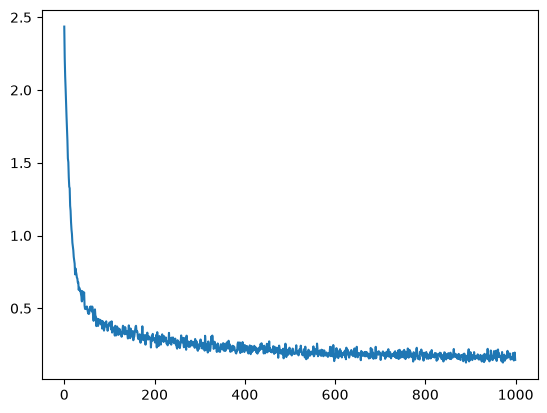

In [46]:
plt.plot(losses)

In [47]:
# test inference

preact1 = X_test @ W1 + b1
act1 = torch.relu(preact1)

preact2 = act1 @ W2 + b2
act2 = torch.relu(preact2)


logits = act2 @ W3 + b3

loss = F.cross_entropy(logits, y_test)

correct = (torch.argmax(logits, 1) == y_test).float()
accuracy = correct.mean().item()
print(f"loss = {loss.item()}, acc = {accuracy}")

loss = 0.1684875637292862, acc = 0.95169997215271
